## Phase 3: Contextual Embeddings
### Research Question
Can we make the representation of a word change depending on the words around it?

For this, we will use BERT (transformer based model), in order to produce contextual embeddings.

In [2]:
from transformers import AutoTokenizer, AutoModel
import torch

tokenizer = AutoTokenizer.from_pretrained('bert-base-uncased')
model = AutoModel.from_pretrained('bert-base-uncased')

model.eval()

sentence_a = "The bank approved my loan."
tokens_a = tokenizer(sentence_a)

print(tokens_a)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 269.78it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


{'input_ids': [101, 1996, 2924, 4844, 2026, 5414, 1012, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1]}


In [3]:
from transformers import AutoTokenizer, AutoModel
import torch

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
bert_model = AutoModel.from_pretrained("bert-base-uncased")

bert_model.eval()

print("BERT loaded successfully!")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 711.30it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT loaded successfully!


In [4]:
sentence_a = "The bank approved my loan."
sentence_b = "The fisherman sat on the bank of the river."

inputs_a = tokenizer(sentence_a, return_tensors="pt")
inputs_b = tokenizer(sentence_b, return_tensors="pt")

tokens_a = tokenizer.convert_ids_to_tokens(inputs_a["input_ids"][0])
tokens_b = tokenizer.convert_ids_to_tokens(inputs_b["input_ids"][0])

print("Sentence A:", tokens_a)
print("Sentence B:", tokens_b)

Sentence A: ['[CLS]', 'the', 'bank', 'approved', 'my', 'loan', '.', '[SEP]']
Sentence B: ['[CLS]', 'the', 'fisherman', 'sat', 'on', 'the', 'bank', 'of', 'the', 'river', '.', '[SEP]']


In [5]:
with torch.no_grad():
    outputs_a = bert_model(**inputs_a)
    outputs_b = bert_model(**inputs_b)

print("Sentence A output shape:", outputs_a.last_hidden_state.shape)
print("Sentence B output shape:", outputs_b.last_hidden_state.shape)

Sentence A output shape: torch.Size([1, 8, 768])
Sentence B output shape: torch.Size([1, 12, 768])


In [6]:
bank_position_a = tokens_a.index("bank")
bank_position_b = tokens_b.index("bank")

print("Bank position in A:", bank_position_a)
print("Bank position in B:", bank_position_b)

Bank position in A: 2
Bank position in B: 6


In [7]:
bank_vector_a = outputs_a.last_hidden_state[0, bank_position_a]
bank_vector_b = outputs_b.last_hidden_state[0, bank_position_b]

print("Bank vector A:", bank_vector_a.shape)
print("Bank vector B:", bank_vector_b.shape)

Bank vector A: torch.Size([768])
Bank vector B: torch.Size([768])


In [8]:
import torch.nn.functional as F

similarity = F.cosine_similarity(
    bank_vector_a.unsqueeze(0),
    bank_vector_b.unsqueeze(0)
)

difference = torch.norm(bank_vector_a - bank_vector_b)

print("Cosine similarity:", similarity.item())
print("Vector difference:", difference.item())

Cosine similarity: 0.4184335470199585
Vector difference: 16.357219696044922


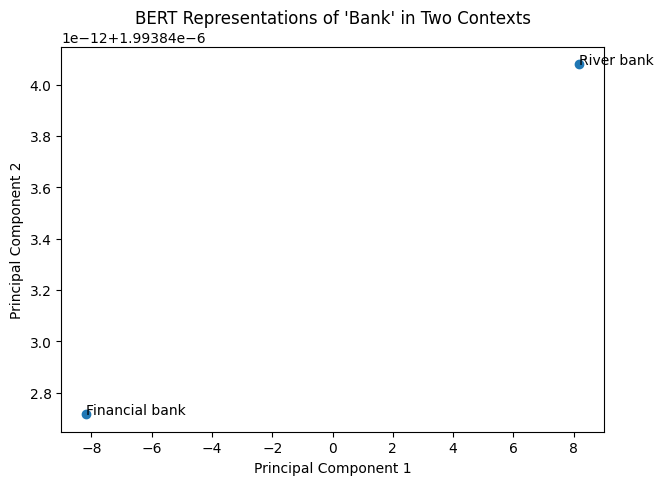

In [9]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np

bank_vectors = torch.stack([
    bank_vector_a,
    bank_vector_b
]).cpu().numpy()

pca = PCA(n_components=2)
bank_vectors_2d = pca.fit_transform(bank_vectors)

plt.figure(figsize=(7, 5))

plt.scatter(
    bank_vectors_2d[:, 0],
    bank_vectors_2d[:, 1]
)

labels = [
    "Financial bank",
    "River bank"
]

for i, label in enumerate(labels):
    plt.annotate(
        label,
        (bank_vectors_2d[i, 0], bank_vectors_2d[i, 1])
    )

plt.title("BERT Representations of 'Bank' in Two Contexts")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()